In [1]:
import pandas as pd
import re
import numpy as np
import os
import csv
import json
import time
from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI

# .env fica na raiz do projeto; o notebook costuma rodar em notebooks/
load_dotenv(Path("..") / ".env")
load_dotenv()

True

In [2]:
provas = pd.read_csv("C:/Users/anara/Desktop/Pesquisa - Tutoria/feedback-open-source/resultados-tecnologia-consolidados_555.csv", sep=None, engine="python")

In [3]:
provas.head(10)

,modelo,prompt_variant,pergunta,resposta_aluno,explicacao,disciplina,feedback
0,gemma4,base,NaN,NaN,NaN,SUAP018548 - Arquitetura de Computadores:Bacha...,Não foi possível avaliar o desempenho do aluno...
1,gemma4,base,What is the significance of architectural patt...,"In software development, architectural pattern...",You correctly identify that without a standard...,Fall_24_CT-365_SE,Você acertou ao mencionar que padrões auxiliam...
2,gemma4,base,Defina transformações e dê três exemplos de tr...,É quando ocorre a mudança da composição do ele...,Os exemplos estão corretos! Atente que não é n...,SUAP017975 - Química Inorgânica:Técnico em Quí...,"Você definiu corretamente a ideia de mudança, ..."
3,gemma4,base,Qual é a principal característica de um softwa...,Consiste em um software de propriedade privada...,Excelente! Você listou corretamente as princip...,06262 - T04 - INTRODUÇÃO À INFORMÁTICA,Você descreveu bem o código fechado e a restri...
4,gemma4,base,Qual é a principal característica de um softwa...,A principal característica do software proprie...,Excelente! O controle exclusivo pela entidade ...,06262 - AG - INTRODUÇÃO À INFORMÁTICA,Você descreveu corretamente o controle de uso ...
5,gemma4,base,Converta os números decimais a seguir para bin...,a) 64 = 1000000 na base 2b) 100 =1100100 na ba...,Correto! 64 em decimal é igual a 1000000 em bi...,SUAP018548 - Arquitetura de Computadores:Bacha...,Você converteu corretamente o número 64 para b...
6,gemma4,base,Um exemplo de sistema operacional comercial de...,Falso,NaN,INTRODUÇÃO À INFORMÁTICA 2020.2,A resposta
7,gemma4,base,Qual é a diferença entre um Hub e um Switch em...,"Hub: envia para todas as máquinas, uma de cada...",Incorreto. O hub pode transmitir dados para to...,06262 - AG - INTRODUÇÃO À INFORMÁTICA,Você acertou que o Switch envia para o destino...
8,gemma4,base,Explique a diferença entre big-endian e little...,Big-endian: guarda o byte mais significativo n...,Correto! Big-endian de fato armazena o byte ma...,SUAP018548 - Arquitetura de Computadores:Bacha...,Você definiu corretamente a ordem de armazenam...
9,gemma4,base,"1) Qual é a suposição ""ingênua"" (naive) fundam...",O algoritmo Naive Bayes assume que todas as fe...,Correto! Essa é exatamente a suposição 'ingênu...,[EC-2025.2] Inteligência Artificial,Você acertou ao mencionar a independência das ...


In [4]:
n_total = 1500
modelos = sorted(provas["modelo"].unique())
n_por_modelo = n_total // len(modelos)  # 499
resto = n_total % len(modelos)          # 2 → dois modelos ficam com 500

frames = []
for i, modelo in enumerate(modelos):
    n = n_por_modelo + (1 if i < resto else 0)
    frames.append(
        provas[provas["modelo"] == modelo].sample(n, random_state=123)
    )

provas_sample = (
    pd.concat(frames)
    .sample(frac=1, random_state=123)  # embaralha a ordem final
    .reset_index(drop=True)
)

print("Total:", len(provas_sample))
print(provas_sample["modelo"].value_counts())
print(provas_sample.groupby(["modelo", "prompt_variant"]).size())

Total: 1500
modelo
phi4-mini    500
qwen3        500
gemma4       500
Name: count, dtype: int64
modelo     prompt_variant
gemma4     base              156
           hattie            180
           nicol             164
phi4-mini  base              156
           hattie            180
           nicol             164
qwen3      base              156
           hattie            180
           nicol             164
dtype: int64


In [5]:
provas_sample['modelo'].unique()

array(['phi4-mini', 'qwen3', 'gemma4'], dtype=object)

In [6]:
for idx, row in provas_sample.iterrows():
    print(idx, row["modelo"], row["prompt_variant"])

print(len(provas_sample))

0 phi4-mini hattie
1 qwen3 base
2 phi4-mini hattie
3 qwen3 base
4 gemma4 hattie
5 gemma4 hattie
6 qwen3 base
7 phi4-mini hattie
8 phi4-mini nicol
9 phi4-mini base
10 phi4-mini nicol
11 qwen3 hattie
12 qwen3 base
13 gemma4 nicol
14 gemma4 hattie
15 gemma4 hattie
16 qwen3 nicol
17 gemma4 nicol
18 phi4-mini hattie
19 phi4-mini base
20 qwen3 hattie
21 gemma4 base
22 qwen3 base
23 gemma4 base
24 phi4-mini hattie
25 gemma4 nicol
26 qwen3 nicol
27 phi4-mini hattie
28 qwen3 hattie
29 phi4-mini hattie
30 qwen3 base
31 qwen3 hattie
32 phi4-mini nicol
33 gemma4 base
34 phi4-mini nicol
35 gemma4 hattie
36 gemma4 hattie
37 phi4-mini nicol
38 qwen3 hattie
39 phi4-mini nicol
40 gemma4 nicol
41 gemma4 base
42 gemma4 base
43 phi4-mini nicol
44 qwen3 base
45 qwen3 hattie
46 phi4-mini base
47 qwen3 nicol
48 qwen3 hattie
49 gemma4 hattie
50 gemma4 nicol
51 phi4-mini hattie
52 phi4-mini hattie
53 gemma4 base
54 phi4-mini hattie
55 gemma4 base
56 gemma4 nicol
57 qwen3 base
58 qwen3 nicol
59 phi4-mini nicol


In [7]:
rubric_eval_prompt = """
Você é um auditor independente especialista em avaliação de feedback educacional
gerado por modelos de linguagem.

Sua tarefa é avaliar a qualidade de um feedback fornecido a um estudante,
considerando:

1. A descrição da atividade;
2. Os objetivos, critérios ou rubrica da atividade;
3. A resposta submetida pelo estudante;
4. O feedback gerado para essa resposta.

Você NÃO deve reescrever o feedback.
Você NÃO deve produzir um novo feedback.
Você NÃO deve sugerir melhorias fora dos campos solicitados.
Você deve apenas classificar o feedback nas 16 dimensões abaixo.

Analise cada dimensão de forma independente.

==================================================
DADOS PARA ANÁLISE
==================================================

DESCRIÇÃO DA ATIVIDADE:
{descricao_atividade}

OBJETIVOS OU RUBRICA DA ATIVIDADE:
{rubrica_atividade}

RESPOSTA DO ESTUDANTE:
{resposta_estudante}

FEEDBACK AVALIADO:
{feedback}

==================================================
PARTE 1 — CONTEÚDO DO FEEDBACK
==================================================

As dimensões de conteúdo devem ser avaliadas em uma escala de 0 a 2.

0 = dimensão ausente ou inadequada
1 = dimensão parcialmente presente
2 = dimensão claramente presente e bem aplicada

1. ALINHAMENTO COM OS OBJETIVOS

Avalia até que ponto os comentários do feedback estão relacionados aos
objetivos, critérios ou requisitos específicos da atividade.

Score 0:
O feedback não relaciona seus comentários aos objetivos ou critérios da atividade.

Score 1:
O feedback menciona os objetivos ou critérios de maneira parcial, vaga ou genérica.

Score 2:
A maior parte dos comentários está claramente relacionada aos objetivos,
critérios ou requisitos específicos da atividade.

2. ESPECIFICIDADE

Avalia se o feedback apresenta orientações detalhadas, concretas e acionáveis.

Score 0:
O feedback é genérico, vago ou não explica como o estudante pode melhorar.

Score 1:
O feedback apresenta alguma orientação útil, mas ainda é pouco detalhado
ou não fornece exemplos concretos.

Score 2:
O feedback oferece orientações claras, detalhadas e acionáveis, incluindo
exemplos ou indicações concretas de como melhorar.

3. TOM MOTIVACIONAL

Avalia se o tom é positivo, encorajador, respeitoso e apropriado ao contexto educacional.

Score 0:
O feedback utiliza tom negativo, desrespeitoso, desencorajador ou inadequado.

Score 1:
O feedback apresenta tom neutro ou parcialmente encorajador, mas de maneira inconsistente.

Score 2:
O feedback mantém um tom positivo, respeitoso, encorajador e construtivo.

4. IDENTIFICAÇÃO DE PONTOS FORTES

Avalia se o feedback identifica aspectos específicos que foram bem realizados
na resposta do estudante.

Score 0:
Não menciona nenhum ponto forte da resposta.

Score 1:
Menciona um ponto forte de maneira genérica, vaga ou pouco relacionada
à resposta do estudante.

Score 2:
Identifica claramente um ou mais pontos fortes específicos da resposta,
explicando por que estão adequados.

5. IDENTIFICAÇÃO DE PONTOS FRACOS

Avalia se o feedback identifica aspectos específicos que precisam ser corrigidos
ou aprimorados.

Score 0:
Não identifica problemas, limitações ou aspectos que precisam melhorar.

Score 1:
Menciona problemas de maneira vaga, genérica ou pouco explicada.

Score 2:
Identifica claramente um ou mais pontos fracos específicos e explica
o que precisa ser aprimorado.

6. LEGIBILIDADE

Avalia se o feedback é claro, compreensível, bem organizado e adequado
ao nível esperado do estudante.

Score 0:
O feedback é confuso, desorganizado, excessivamente complexo ou difícil de compreender.

Score 1:
O feedback é parcialmente compreensível, mas contém problemas de organização,
clareza, linguagem ou excesso de complexidade.

Score 2:
O feedback é claro, organizado, objetivo e facilmente compreensível pelo estudante.

==================================================
PARTE 2 — EFETIVIDADE DO FEEDBACK
==================================================

As dimensões de efetividade devem ser avaliadas de forma binária.

0 = o componente não está presente
1 = o componente está presente

Considere que uma dimensão somente deve receber 1 quando houver evidência
clara no texto do feedback.

7. FEED UP — CLAREZA SOBRE OS OBJETIVOS

Avalia se o feedback esclarece ou relembra o objetivo, o resultado esperado,
os critérios de sucesso ou o que deveria ser alcançado na atividade.

Score 0:
Não esclarece os objetivos ou critérios de sucesso.

Score 1:
Esclarece ou relembra os objetivos, critérios ou resultados esperados.

8. FEED BACK — PROGRESSO EM RELAÇÃO AO OBJETIVO

Avalia se o feedback informa como o desempenho atual do estudante se compara
ao objetivo ou ao resultado esperado.

Score 0:
Não informa o que foi alcançado ou o que ainda está distante do objetivo.

Score 1:
Explica o desempenho atual do estudante em relação aos objetivos ou critérios.

9. FEED FORWARD — PRÓXIMOS PASSOS

Avalia se o feedback indica ações futuras, próximos passos ou estratégias
para melhorar o trabalho ou a aprendizagem.

Score 0:
Não fornece orientação sobre o que fazer em seguida.

Score 1:
Apresenta ações, estratégias ou próximos passos para melhoria.

10. FEEDBACK SOBRE A TAREFA

Avalia se o feedback comenta diretamente a correção, completude, precisão
ou qualidade do produto final apresentado pelo estudante.

Pode incluir:
- identificação de respostas corretas ou incorretas;
- falta de informações;
- erros conceituais;
- adequação aos requisitos;
- qualidade do resultado final.

Score 0:
Não apresenta comentários sobre a execução ou o resultado da tarefa.

Score 1:
Apresenta comentários claros sobre a correção, qualidade ou completude da tarefa.

11. FEEDBACK SOBRE O PROCESSO

Avalia se o feedback comenta as estratégias, procedimentos, raciocínio
ou métodos utilizados para realizar a atividade.

Score 0:
Não aborda o processo utilizado pelo estudante.

Score 1:
Aborda como o estudante pensou, organizou, analisou ou executou a atividade.

12. FEEDBACK SOBRE AUTORREGULAÇÃO

Avalia se o feedback incentiva o estudante a monitorar, revisar, avaliar
ou controlar o próprio processo de aprendizagem.

Pode incluir:
- autoavaliação;
- revisão do próprio trabalho;
- planejamento;
- monitoramento da compreensão;
- verificação de erros;
- escolha de estratégias;
- reflexão sobre o próprio desempenho.

Score 0:
Não apresenta elementos relacionados à autorregulação.

Score 1:
Incentiva claramente a reflexão, o monitoramento ou a revisão autônoma.

13. FEEDBACK SOBRE O EU

Avalia se o feedback apresenta comentários pessoais dirigidos ao estudante
como indivíduo, em vez de se concentrar na tarefa, no processo ou na estratégia.

Exemplos:
- “Você é muito inteligente.”
- “Você é um excelente aluno.”
- “Você não leva jeito para isso.”

Score 0:
Não apresenta comentários pessoais sobre o estudante.

Score 1:
Apresenta elogios ou críticas dirigidos à pessoa, sem relação direta
com o desempenho específico na tarefa.

Atenção:
Não confunda um tom motivacional com feedback sobre o eu.
Comentários como “continue se esforçando” não são necessariamente feedback
sobre o eu, caso estejam vinculados à tarefa ou ao processo.

==================================================
PARTE 3 — ALUCINAÇÕES
==================================================

As dimensões de alucinação devem ser avaliadas de forma binária.

0 = a alucinação não foi identificada
1 = a alucinação foi identificada

Somente classifique como alucinação quando houver evidência clara.
Não considere simples diferenças de interpretação como alucinação.

14. ALUCINAÇÃO EM CONFLITO COM A ENTRADA

Avalia se o feedback contradiz, altera ou inventa informações sobre:

- a atividade;
- a rubrica;
- a resposta do estudante;
- dados presentes nos materiais fornecidos.

Score 0:
Não há informações que contradigam ou inventem elementos da entrada.

Score 1:
O feedback atribui ao estudante, à resposta ou à atividade alguma informação
que não existe ou que contradiz os dados fornecidos.

15. ALUCINAÇÃO EM CONFLITO COM O CONTEXTO

Avalia se o feedback contém afirmações internamente contraditórias.

Score 0:
O texto é internamente consistente.

Score 1:
O feedback apresenta duas ou mais afirmações incompatíveis entre si.

Exemplo:
Primeiro afirma que o estudante explicou corretamente um conceito e,
posteriormente, afirma que esse conceito não foi apresentado.

16. ALUCINAÇÃO EM CONFLITO COM FATOS

Avalia se o feedback contém afirmações que contradizem fatos objetivos,
conhecimentos consolidados ou informações verificáveis.

Score 0:
Não apresenta afirmações factualmente incorretas identificáveis.

Score 1:
Apresenta pelo menos uma afirmação claramente incompatível com fatos conhecidos.

Caso não seja possível verificar uma afirmação com segurança, atribua 0
e registre a incerteza na justificativa.

==================================================
REGRAS DE AVALIAÇÃO
==================================================

- Avalie somente o feedback fornecido.
- Use a descrição da atividade, a rubrica e a resposta do estudante como referência.
- Não premie o feedback apenas por ser longo.
- Não penalize o feedback apenas por ser curto.
- Não infira qualidades que não estejam explicitamente presentes.
- Não atribua uma dimensão com base apenas em uma frase genérica.
- As dimensões podem receber avaliações diferentes.
- Um feedback pode ter bom tom motivacional e baixa especificidade.
- Um feedback pode identificar erros corretamente, mas não apresentar feed forward.
- Um comentário pode ser simultaneamente feedback sobre tarefa e feed back.
- A presença de uma alucinação não implica automaticamente nota baixa
  em todas as outras dimensões.
- Não inclua texto fora do JSON solicitado.

==================================================
FORMATO DE SAÍDA
==================================================

Retorne exclusivamente um objeto JSON válido seguindo exatamente esta estrutura:

{
  "conteudo": {
    "alinhamento_objetivos": {
      "score": 0,
      "justificativa": ""
    },
    "especificidade": {
      "score": 0,
      "justificativa": ""
    },
    "tom_motivacional": {
      "score": 0,
      "justificativa": ""
    },
    "pontos_fortes": {
      "score": 0,
      "justificativa": ""
    },
    "pontos_fracos": {
      "score": 0,
      "justificativa": ""
    },
    "legibilidade": {
      "score": 0,
      "justificativa": ""
    }
  },
  "efetividade": {
    "feed_up": {
      "score": 0,
      "justificativa": ""
    },
    "feed_back": {
      "score": 0,
      "justificativa": ""
    },
    "feed_forward": {
      "score": 0,
      "justificativa": ""
    },
    "feedback_tarefa": {
      "score": 0,
      "justificativa": ""
    },
    "feedback_processo": {
      "score": 0,
      "justificativa": ""
    },
    "feedback_autorregulacao": {
      "score": 0,
      "justificativa": ""
    },
    "feedback_eu": {
      "score": 0,
      "justificativa": ""
    }
  },
  "alucinacoes": {
    "conflito_entrada": {
      "score": 0,
      "justificativa": ""
    },
    "conflito_contexto": {
      "score": 0,
      "justificativa": ""
    },
    "conflito_fatos": {
      "score": 0,
      "justificativa": ""
    }
  },
  "resumo_avaliacao": {
    "pontuacao_conteudo": 0,
    "pontuacao_maxima_conteudo": 12,
    "componentes_efetividade_presentes": 0,
    "total_componentes_efetividade": 7,
    "alucinacoes_detectadas": 0,
    "principais_observacoes": ""
  }
}
"""

In [8]:
prompts = []
for _, row in provas_sample.iterrows():
    prompts.append(
        rubric_eval_prompt
        .replace("{descricao_atividade}", str(row["pergunta"]))
        .replace("{rubrica_atividade}", str(row["explicacao"]))
        .replace("{resposta_estudante}", str(row["resposta_aluno"]))
        .replace("{feedback}", str(row["feedback"]))
    )

print(f"Total de prompts gerados: {len(prompts)}")

Total de prompts gerados: 1500


In [10]:
api_key = os.getenv("CHAT_API_KEY")
if not api_key:
    raise ValueError(
        "OPENAI_API_KEY não encontrada. Confira o .env na raiz do projeto "
        f"e o diretório atual ({os.getcwd()})."
    )

client = OpenAI(api_key=api_key)
print("Cliente OpenAI configurado:", api_key[:6] + "...")

Cliente OpenAI configurado: sk-pro...


In [11]:
print("Provedor ativo: OpenAI Batch API")

Provedor ativo: OpenAI Batch API


In [12]:
print("CWD:", os.getcwd())
print("OPENAI_API_KEY existe?", os.getenv("CHAT_API_KEY") is not None)

CWD: c:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\notebooks
OPENAI_API_KEY existe? True


In [13]:
# Célula de verificação duplicada — pode pular.
# Use a célula anterior para checar OPENAI_API_KEY.

CWD: c:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\notebooks
load_dotenv retornou: True
GOOGLE_API_KEY existe? True


In [13]:
MODELO_GPT = "gpt-5-mini"  # fallback: "gpt-5-mini-2025-08-07"
POLL_INTERVAL_SEGUNDOS = 30
TAMANHO_MINI_BATCH = 250          # requests por job
PAUSA_ENTRE_BATCHES_SEGUNDOS = 120  # pausa após cada mini-batch (exceto o último)
PROGRESSO_JSON = "batch_rubrica_gpt_progress.json"
NOME_ARQUIVO_CSV = (
    Path("..") / "resultado_rubrica" / "prova-tecnologia-results-1500-rubrica-16dim-gpt5mini.csv"
)

In [14]:
cabecalhos = ["modelo","prompt_variant","pergunta","resposta_aluno","explicacao","disciplina","feedback", "analise_feedback"]

In [15]:
n_batches = (len(prompts) + TAMANHO_MINI_BATCH - 1) // TAMANHO_MINI_BATCH
print(f"Modelo: {MODELO_GPT}")
print(f"Prompts: {len(prompts)}")
print(f"Mini-batches: {n_batches} x até {TAMANHO_MINI_BATCH}")
print(f"Pausa entre batches: {PAUSA_ENTRE_BATCHES_SEGUNDOS}s")
print(f"CSV de saída: {NOME_ARQUIVO_CSV.resolve()}")

Modelo: gpt-5-mini
Prompts: 1500
Mini-batches: 6 x até 250
Pausa entre batches: 120s
CSV de saída: C:\Users\anara\Desktop\Pesquisa - Tutoria\feedback-open-source\resultado_rubrica\prova-tecnologia-results-1500-rubrica-16dim-gpt5mini.csv


In [17]:
estados_finais = {"completed", "failed", "cancelled", "expired"}


def montar_request(prompt_texto: str, key: str) -> dict:
    return {
        "custom_id": key,
        "method": "POST",
        "url": "/v1/chat/completions",
        "body": {
            "model": MODELO_GPT,
            "response_format": {"type": "json_object"},
            "messages": [{"role": "user", "content": prompt_texto}],
        },
    }


def extrair_texto_response(body):
    if body is None or not isinstance(body, dict):
        return None
    if body.get("error"):
        return None
    try:
        return body["choices"][0]["message"]["content"]
    except (KeyError, IndexError, TypeError):
        return None


def coletar_resultados_batch(batch_job, keys_esperadas) -> dict:
    """Retorna {key: {"texto": str|None, "erro": str|None}}."""
    resultados = {}

    def registrar(key, texto=None, erro=None):
        resultados[str(key)] = {"texto": texto, "erro": erro}

    if not batch_job.output_file_id:
        raise RuntimeError("Batch concluído, mas output_file_id está vazio.")

    print(f"  Baixando resultados: {batch_job.output_file_id}")
    conteudo = client.files.content(batch_job.output_file_id).text

    for linha in conteudo.splitlines():
        if not linha.strip():
            continue
        item = json.loads(linha)
        key = item.get("custom_id")
        if item.get("error"):
            registrar(key, erro=str(item["error"]))
            continue

        resp = item.get("response")
        if resp and resp.get("status_code") == 200:
            texto = extrair_texto_response(resp.get("body"))
            if texto:
                registrar(key, texto=texto)
            else:
                registrar(key, erro="resposta_vazia")
        else:
            body = (resp or {}).get("body", {})
            erro_msg = body.get("error", resp or "sem response")
            registrar(key, erro=str(erro_msg))

    return resultados


def aguardar_batch(batch_job):
    while True:
        batch_job = client.batches.retrieve(batch_job.id)
        estado = batch_job.status
        print(f"  Estado: {estado}")
        if estado in estados_finais:
            break
        time.sleep(POLL_INTERVAL_SEGUNDOS)

    if batch_job.status != "completed":
        raise RuntimeError(
            f"Mini-batch falhou com estado {batch_job.status}. "
            f"Erro: {getattr(batch_job, 'errors', None)}"
        )
    return batch_job


def analise_de_item(item: dict):
    """Retorna (analise_json_str, sucesso)."""
    texto = item.get("texto")
    erro = item.get("erro")
    if texto:
        try:
            dados = json.loads(texto)
            return json.dumps(dados, ensure_ascii=False), True
        except json.JSONDecodeError:
            return json.dumps(
                {"erro": "json_invalido", "raw": texto},
                ensure_ascii=False,
            ), False
    return json.dumps(
        {"erro": "batch_sem_resposta", "detalhe": str(erro)},
        ensure_ascii=False,
    ), False


def carregar_progresso():
    if os.path.isfile(PROGRESSO_JSON):
        with open(PROGRESSO_JSON, encoding="utf-8") as f:
            data = json.load(f)
        return set(str(x) for x in data.get("concluidos", []))
    return set()


def salvar_progresso(concluidos):
    with open(PROGRESSO_JSON, "w", encoding="utf-8") as f:
        json.dump({"concluidos": sorted(concluidos, key=lambda x: int(x))}, f)


# Retomada: pula índices já concluídos
ja_salvos = carregar_progresso()
indices_pendentes = [i for i in range(len(prompts)) if str(i) not in ja_salvos]
print(f"Já concluídos: {len(ja_salvos)} | Pendentes: {len(indices_pendentes)}")

NOME_ARQUIVO_CSV.parent.mkdir(parents=True, exist_ok=True)
arquivo_existe = NOME_ARQUIVO_CSV.is_file()
ok_total, falhas_total = 0, 0
jobs_criados = []

with open(NOME_ARQUIVO_CSV, "a", newline="", encoding="utf-8") as csv_file:
    escritor = csv.DictWriter(csv_file, fieldnames=cabecalhos)
    if not arquivo_existe:
        escritor.writeheader()

    total_mini = (len(indices_pendentes) + TAMANHO_MINI_BATCH - 1) // max(TAMANHO_MINI_BATCH, 1)

    if total_mini == 0:
        print("Nada pendente para processar.")
    else:
        for b in range(total_mini):
            inicio = b * TAMANHO_MINI_BATCH
            fim = min(inicio + TAMANHO_MINI_BATCH, len(indices_pendentes))
            lote_idxs = indices_pendentes[inicio:fim]

            print(
                f"\n=== Mini-batch {b+1}/{total_mini} | "
                f"keys {lote_idxs[0]}..{lote_idxs[-1]} ({len(lote_idxs)} reqs) ==="
            )

            jsonl_nome = f"batch_rubrica_gpt_part_{b+1:02d}.jsonl"
            with open(jsonl_nome, "w", encoding="utf-8") as f:
                for i in lote_idxs:
                    f.write(
                        json.dumps(montar_request(prompts[i], str(i)), ensure_ascii=False)
                        + "\n"
                    )

            tamanho_mb = os.path.getsize(jsonl_nome) / (1024 * 1024)
            print(f"  JSONL: {jsonl_nome} ({tamanho_mb:.2f} MB)")

            with open(jsonl_nome, "rb") as f:
                uploaded_file = client.files.create(file=f, purpose="batch")
            print(f"  Upload: {uploaded_file.id}")

            batch_job = client.batches.create(
                input_file_id=uploaded_file.id,
                endpoint="/v1/chat/completions",
                completion_window="24h",
                metadata={"description": f"rubrica-16dim-gpt-part-{b+1}"},
            )
            print(f"  Job: {batch_job.id}")
            jobs_criados.append(batch_job.id)

            batch_job = aguardar_batch(batch_job)
            resultados = coletar_resultados_batch(batch_job, lote_idxs)
            print(f"  Respostas neste lote: {len(resultados)}")

            for i in lote_idxs:
                key = str(i)
                item = resultados.get(key, {"texto": None, "erro": "ausente_no_retorno"})
                analise, sucesso = analise_de_item(item)
                if sucesso:
                    ok_total += 1
                else:
                    falhas_total += 1

                linha = provas_sample.iloc[i]
                escritor.writerow(
                    {
                        "modelo": linha["modelo"],
                        "prompt_variant": linha["prompt_variant"],
                        "pergunta": linha["pergunta"],
                        "resposta_aluno": linha["resposta_aluno"],
                        "explicacao": linha["explicacao"],
                        "disciplina": linha["disciplina"],
                        "feedback": linha["feedback"],
                        "analise_feedback": analise,
                    }
                )
                ja_salvos.add(key)

            csv_file.flush()
            salvar_progresso(ja_salvos)
            print(f"  CSV atualizado (+{len(lote_idxs)} linhas)")

            if b < total_mini - 1:
                print(
                    f"  Pausando {PAUSA_ENTRE_BATCHES_SEGUNDOS}s antes do próximo mini-batch..."
                )
                time.sleep(PAUSA_ENTRE_BATCHES_SEGUNDOS)

print("\nConcluído.")
print(f"CSV: {NOME_ARQUIVO_CSV.resolve()}")
print(f"OK: {ok_total} | Falhas/parse: {falhas_total}")
print(f"Jobs: {jobs_criados}")
print(
    "Para recomeçar do zero, apague o CSV e o arquivo "
    f"{PROGRESSO_JSON} antes de rodar esta célula."
)


Já concluídos: 0 | Pendentes: 1500

=== Mini-batch 1/6 | keys 0..249 (250 reqs) ===
  JSONL: batch_rubrica_gpt_part_01.jsonl (3.10 MB)
  Upload: file-BJuUAp8kE7kxyhjGx8RzWn
  Job: batch_6ab2dcfd22308190bf2a4cec486b7fbe
  Estado: validating
  Estado: validating
  Estado: validating
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_progress
  Estado: in_p

In [18]:
batch_id = "batch_6ab2dcfd22308190bf2a4cec486b7fbe"  # cole o ID atual
job = client.batches.retrieve(batch_id)
print("status:", job.status)
print("created_at:", job.created_at)
print("request_counts:", job.request_counts)
print("output_file_id:", job.output_file_id)
print("error_file_id:", job.error_file_id)

status: completed
created_at: 1790106877
request_counts: BatchRequestCounts(completed=250, failed=0, total=250)
output_file_id: file-4nEZ7ZrsikYTS4oa8LLtaH
error_file_id: None


## Heatmap — Escore Likert médio (1–3) por dimensão de conteúdo

Escala Likert **1–3** obtida a partir dos scores de conteúdo da rubrica (0–2 → +1).

Fonte: `resultado_rubrica/prova-tecnologia-results-1500-rubrica-16dim-gpt5mini.csv`

- **(a)** média por **modelo gerador** (SLM)
- **(b)** média por **estratégia de prompt** (Base / Nicol / Hattie)

Linhas válidas: 1249 / 1500
Observações no long format: 7494


,Alinhamento c/ objetivos,Especificidade,Tom motivacional,Pontos fortes,Pontos fracos,Legibilidade
modelo,,,,,,
gemma4,2.87,2.69,2.89,2.68,2.73,2.98
phi4-mini,2.76,2.39,2.66,2.67,2.72,2.98
qwen3,2.90,2.46,2.64,2.83,2.69,2.97


,Alinhamento c/ objetivos,Especificidade,Tom motivacional,Pontos fortes,Pontos fracos,Legibilidade
prompt,,,,,,
Base,2.84,2.55,2.73,2.78,2.77,2.98
Nicol,2.87,2.53,2.88,2.79,2.68,2.99
Hattie,2.82,2.47,2.58,2.62,2.70,2.97


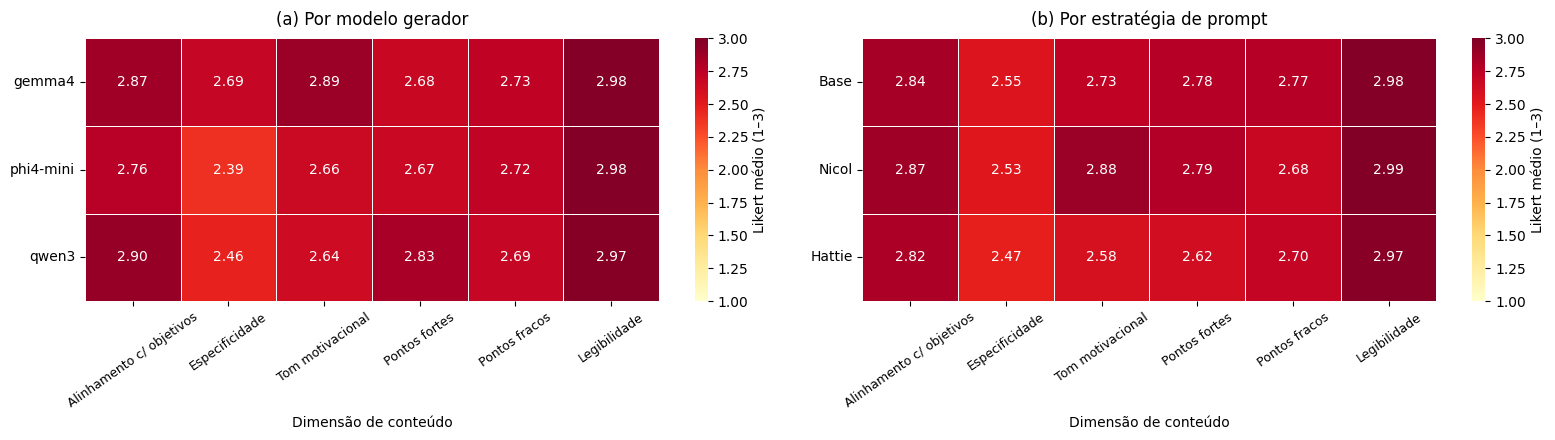

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

CAMINHO_RESULTADOS = Path("..") / "resultado_rubrica" / "prova-tecnologia-results-1500-rubrica-16dim-gpt5mini.csv"

DIMENSOES_CONTEUDO = [
    "alinhamento_objetivos",
    "especificidade",
    "tom_motivacional",
    "pontos_fortes",
    "pontos_fracos",
    "legibilidade",
]

ROTULOS_DIMENSAO = {
    "alinhamento_objetivos": "Alinhamento c/ objetivos",
    "especificidade": "Especificidade",
    "tom_motivacional": "Tom motivacional",
    "pontos_fortes": "Pontos fortes",
    "pontos_fracos": "Pontos fracos",
    "legibilidade": "Legibilidade",
}

ROTULO_PROMPT = {"base": "Base", "nicol": "Nicol", "hattie": "Hattie"}


def extrair_scores_conteudo_likert(valor):
    """Extrai scores das 6 dimensões de conteúdo e converte 0–2 → Likert 1–3."""
    try:
        if pd.isna(valor):
            return None

        dados = json.loads(valor) if isinstance(valor, str) else valor
        if "erro" in dados:
            return None

        conteudo = dados.get("conteudo", {})
        scores = {}
        for dim in DIMENSOES_CONTEUDO:
            info = conteudo.get(dim)
            if info is None and dim == "pontos_fracos":
                info = conteudo.get("pontos_fraços")
            if info is None:
                return None
            scores[dim] = info["score"] + 1

        return scores
    except Exception:
        return None


def heatmap_conteudo(pivot, titulo, ax):
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="YlOrRd",
        vmin=1,
        vmax=3,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Likert médio (1–3)"},
        ax=ax,
    )
    ax.set_title(titulo, fontsize=12, pad=10)
    ax.set_xlabel("Dimensão de conteúdo")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=35, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=10)


df_rubrica = pd.read_csv(CAMINHO_RESULTADOS)
scores_conteudo = df_rubrica["analise_feedback"].apply(extrair_scores_conteudo_likert)

linhas = []
for idx, scores in scores_conteudo.items():
    if scores is None:
        continue
    row = df_rubrica.loc[idx]
    for dim, likert in scores.items():
        linhas.append(
            {
                "modelo": row["modelo"],
                "prompt_variant": row["prompt_variant"],
                "dimensao": dim,
                "likert": likert,
            }
        )

df_long = pd.DataFrame(linhas)
print(f"Linhas válidas: {scores_conteudo.notna().sum()} / {len(df_rubrica)}")
print(f"Observações no long format: {len(df_long)}")

# (a) Por modelo gerador
pivot_modelo = (
    df_long.groupby(["modelo", "dimensao"])["likert"]
    .mean()
    .unstack("dimensao")[DIMENSOES_CONTEUDO]
)
pivot_modelo.columns = [ROTULOS_DIMENSAO[c] for c in pivot_modelo.columns]

# (b) Por estratégia de prompt
df_long["prompt"] = df_long["prompt_variant"].map(ROTULO_PROMPT)
pivot_prompt = (
    df_long.groupby(["prompt", "dimensao"])["likert"]
    .mean()
    .unstack("dimensao")[DIMENSOES_CONTEUDO]
)
pivot_prompt = pivot_prompt.reindex(["Base", "Nicol", "Hattie"])
pivot_prompt.columns = [ROTULOS_DIMENSAO[c] for c in pivot_prompt.columns]

display(pivot_modelo.round(2))
display(pivot_prompt.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
heatmap_conteudo(pivot_modelo, "(a) Por modelo gerador", axes[0])
heatmap_conteudo(pivot_prompt, "(b) Por estratégia de prompt", axes[1])
plt.tight_layout()
plt.show()